# End-to-End Machine Learning Prediction Project
## E-Commerce Shipment Delivery Prediction

**Dataset:** `Train(8).csv`  
**Problem Type:** Binary Classification  
**Target Variable:** `Reached.on.Time_Y.N`

### Problem Statement
The objective is to predict whether an e-commerce shipment will reach on time based on shipment, product, customer, and delivery-related features.


## Import Required Libraries

We import the libraries needed for data handling, visualization, preprocessing, model training, evaluation, hyperparameter tuning, and saving the final model.

**Why:** Keeping imports in one place makes the notebook easier to understand and reproduce.

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully.


## 1. Load the Dataset

The CSV file is loaded from the same directory as this notebook.

**Why:** We first need the raw dataset before performing any analysis or preprocessing.

**Expected output:** The first few rows of the dataset should be displayed.

In [2]:
import os
import pandas as pd

# Load the dataset uploaded with this notebook
data_path = "/mnt/data/Train(8).csv"

if not os.path.exists(data_path):
    # Fallback for running the notebook outside the current environment
    data_path = "Train(8).csv"

if not os.path.exists(data_path):
    raise FileNotFoundError(
        "Dataset not found. Keep Train(8).csv in the same folder as the notebook."
    )

df = pd.read_csv(data_path)

print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())


Dataset loaded successfully.
Shape: (10999, 12)


,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
0,1,D,Flight,4,2,177,3,low,F,44,1233,1
1,2,F,Flight,4,5,216,2,low,M,59,3088,1
2,3,A,Flight,2,2,183,4,low,M,48,3374,1
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1


## 2. Understand the Dataset

We inspect the data types, number of rows and columns, and summary statistics.

**Why:** Understanding the structure helps us decide which columns are numerical, which are categorical, and which preprocessing methods are appropriate.

In [3]:
print("Dataset information:")
df.info()

print("\nColumn names:")
print(df.columns.tolist())

print("\nSummary statistics:")
display(df.describe(include="all").T)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10999 entries, 0 to 10998
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ID                   10999 non-null  int64 
 1   Warehouse_block      10999 non-null  object
 2   Mode_of_Shipment     10999 non-null  object
 3   Customer_care_calls  10999 non-null  int64 
 4   Customer_rating      10999 non-null  int64 
 5   Cost_of_the_Product  10999 non-null  int64 
 6   Prior_purchases      10999 non-null  int64 
 7   Product_importance   10999 non-null  object
 8   Gender               10999 non-null  object
 9   Discount_offered     10999 non-null  int64 
 10  Weight_in_gms        10999 non-null  int64 
 11  Reached.on.Time_Y.N  10999 non-null  int64 
dtypes: int64(8), object(4)
memory usage: 1.0+ MB

Column names:
['ID', 'Warehouse_block', 'Mode_of_Shipment', 'Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_p

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,10999.0,NaN,NaN,NaN,5500.0,3175.28214,1.0,2750.5,5500.0,8249.5,10999.0
Warehouse_block,10999,5,F,3666,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Mode_of_Shipment,10999,3,Ship,7462,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_care_calls,10999.0,NaN,NaN,NaN,4.054459,1.14149,2.0,3.0,4.0,5.0,7.0
Customer_rating,10999.0,NaN,NaN,NaN,2.990545,1.413603,1.0,2.0,3.0,4.0,5.0
Cost_of_the_Product,10999.0,NaN,NaN,NaN,210.196836,48.063272,96.0,169.0,214.0,251.0,310.0
Prior_purchases,10999.0,NaN,NaN,NaN,3.567597,1.52286,2.0,3.0,3.0,4.0,10.0
Product_importance,10999,3,low,5297,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,10999,2,F,5545,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Discount_offered,10999.0,NaN,NaN,NaN,13.373216,16.205527,1.0,4.0,7.0,10.0,65.0


## 3. Define Features and Target

The target column is `Reached.on.Time_Y.N`.

- `1` = shipment reached on time
- `0` = shipment did not reach on time

`ID` is an identifier, not a meaningful predictive feature, so it will be removed from the model.

**Why:** Including an ID can allow a model to learn meaningless row/order information instead of useful shipment patterns.

In [4]:
target = "Reached.on.Time_Y.N"

print("Target variable:", target)
print("\nTarget values:")
print(df[target].value_counts().sort_index())

print("\nTarget percentages:")
print((df[target].value_counts(normalize=True).sort_index() * 100).round(2))

Target variable: Reached.on.Time_Y.N

Target values:
Reached.on.Time_Y.N
0    4436
1    6563
Name: count, dtype: int64

Target percentages:
Reached.on.Time_Y.N
0    40.33
1    59.67
Name: proportion, dtype: float64


## 4. Exploratory Data Analysis – Target Distribution

We visualize the number of on-time and late shipments.

**Why:** Target balance is important for classification. If one class is much larger, accuracy alone may not be enough to judge the model.

**Output meaning:** The chart shows how many shipments belong to each class.

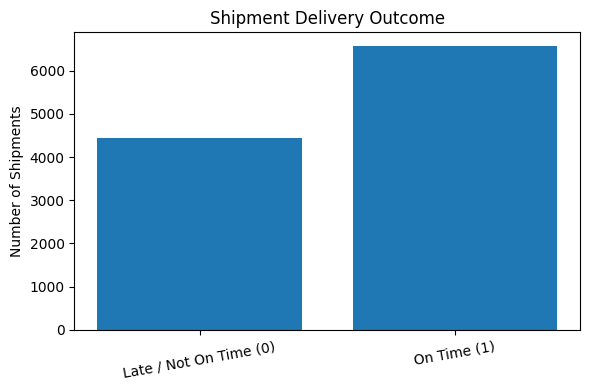

In [5]:
target_counts = df[target].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(["Late / Not On Time (0)", "On Time (1)"], target_counts.values)
plt.title("Shipment Delivery Outcome")
plt.ylabel("Number of Shipments")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

## 5. Exploratory Data Analysis – Categorical Features

We inspect the distribution of the main categorical variables.

**Why:** Categorical features such as warehouse block, shipment mode, product importance, and gender may contain useful patterns for prediction.


--- Warehouse_block ---


,count
Warehouse_block,
F,3666
D,1834
A,1833
B,1833
C,1833


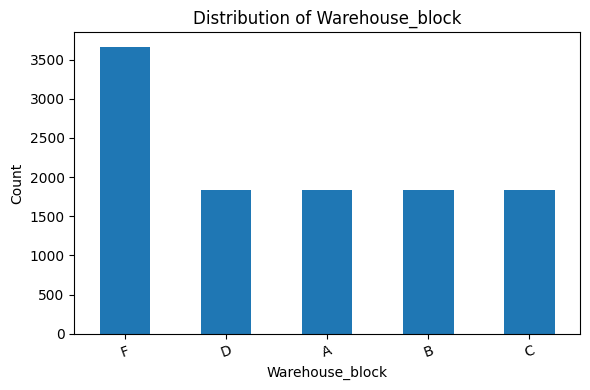


--- Mode_of_Shipment ---


,count
Mode_of_Shipment,
Ship,7462
Flight,1777
Road,1760


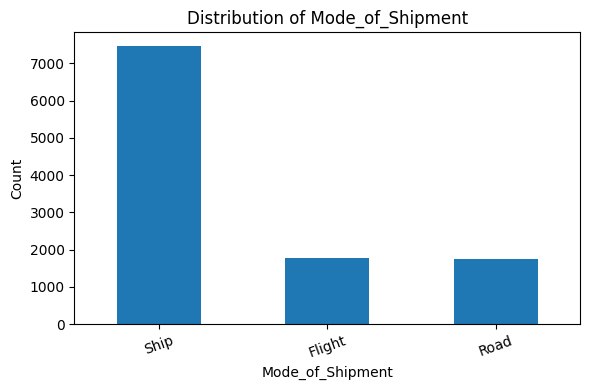


--- Product_importance ---


,count
Product_importance,
low,5297
medium,4754
high,948


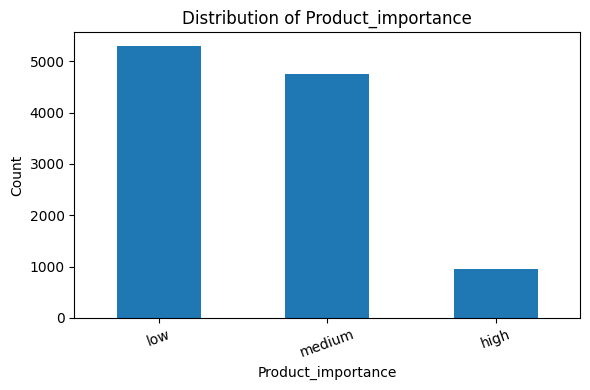


--- Gender ---


,count
Gender,
F,5545
M,5454


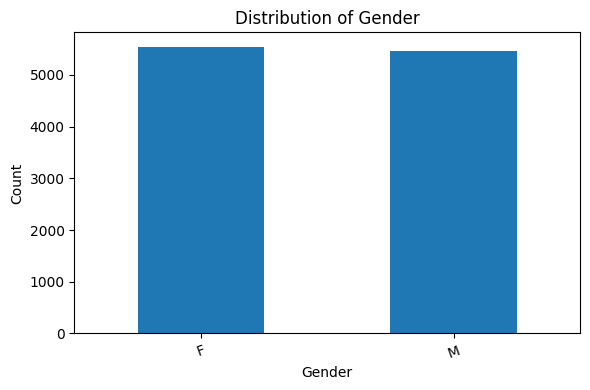

In [6]:
categorical_columns = [
    "Warehouse_block",
    "Mode_of_Shipment",
    "Product_importance",
    "Gender"
]

for col in categorical_columns:
    print(f"\n--- {col} ---")
    display(df[col].value_counts().to_frame("count"))

    plt.figure(figsize=(6, 4))
    df[col].value_counts().plot(kind="bar")
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

## 6. Exploratory Data Analysis – Numerical Features

We inspect the numerical columns and their distributions.

**Why:** Distribution plots help us identify unusual values and understand the scale of each numerical feature.

We do not automatically delete outliers because an unusual value can be a genuine business observation.

In [7]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
numeric_columns

['ID',
 'Customer_care_calls',
 'Customer_rating',
 'Cost_of_the_Product',
 'Prior_purchases',
 'Discount_offered',
 'Weight_in_gms',
 'Reached.on.Time_Y.N']

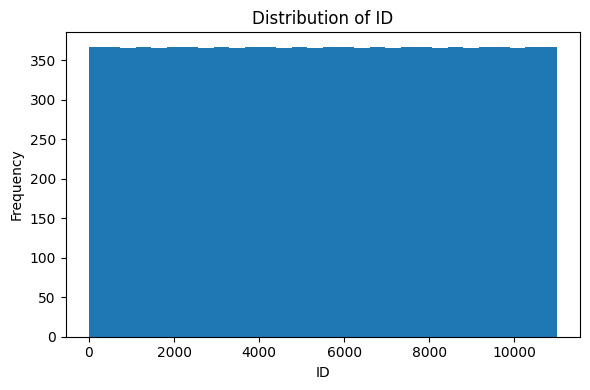

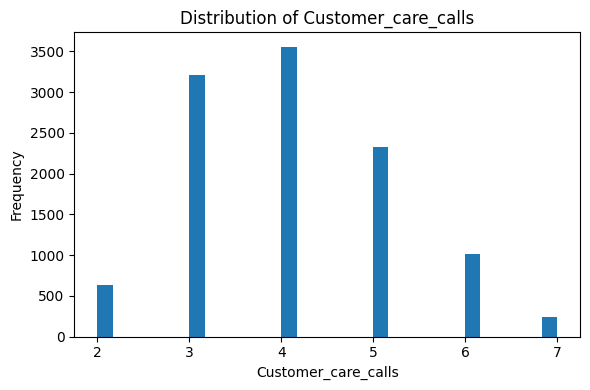

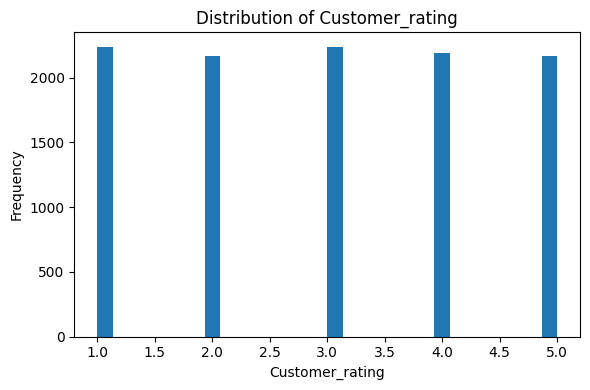

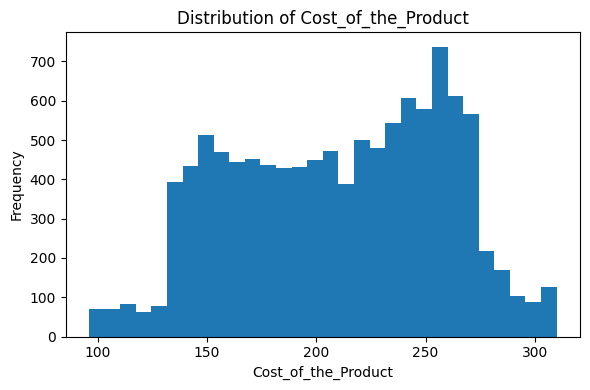

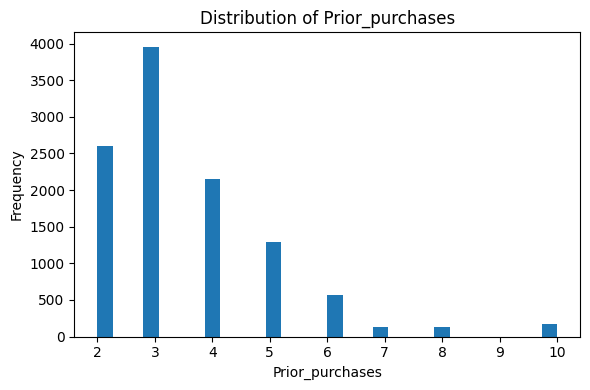

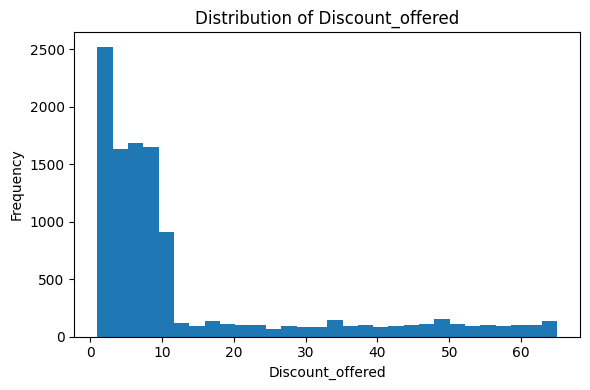

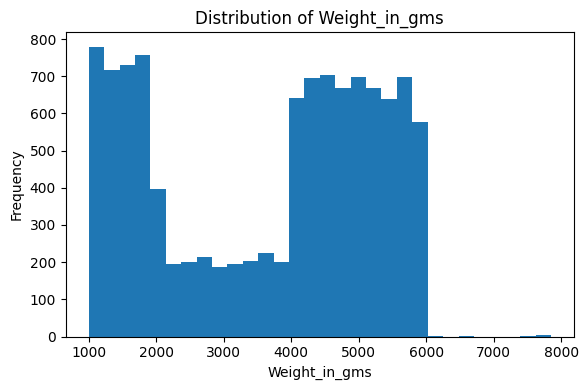

In [8]:
for col in numeric_columns:
    if col == target:
        continue

    plt.figure(figsize=(6, 4))
    plt.hist(df[col], bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

## 7. Check Missing Values

We check every column for missing values.

**Why:** Most ML algorithms cannot directly work with missing values. If missing values exist, they should be handled inside the preprocessing pipeline.

**Output meaning:** A value of zero means that column has no missing values.

In [9]:
missing_values = df.isnull().sum().sort_values(ascending=False)
display(missing_values.to_frame("missing_count"))

print("Total missing values:", int(df.isnull().sum().sum()))

,missing_count
ID,0
Warehouse_block,0
Mode_of_Shipment,0
Customer_care_calls,0
Customer_rating,0
Cost_of_the_Product,0
Prior_purchases,0
Product_importance,0
Gender,0
Discount_offered,0


Total missing values: 0


## 8. Check Duplicate Records

Duplicate records can give some observations extra influence during model training.

**Why:** We check duplicates before training so that repeated rows do not unnecessarily affect the models.

If duplicates are found, they are removed. In this dataset, the check is expected to show whether any exact duplicate rows are present.

In [10]:
duplicate_count = int(df.duplicated().sum())
print("Number of duplicate rows:", duplicate_count)

if duplicate_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Duplicates removed.")
else:
    print("No duplicate rows found; no rows were removed.")

Number of duplicate rows: 0
No duplicate rows found; no rows were removed.


## 9. Outlier Analysis

We use the IQR rule to count potential outliers in numerical columns.

**Why:** Outlier detection is useful for understanding the data. However, we will not blindly remove every detected outlier because values such as discount and package weight can be legitimate observations.

**Decision:** We will retain genuine observations and let the models handle the distributions. The preprocessing pipeline will focus on missing values, encoding, and scaling where appropriate.

In [11]:
def iqr_outlier_count(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return int(((series < lower) | (series > upper)).sum())

outlier_summary = []
for col in numeric_columns:
    if col != target:
        outlier_summary.append({
            "Feature": col,
            "Potential_Outliers_IQR": iqr_outlier_count(df[col])
        })

outlier_summary = pd.DataFrame(outlier_summary).sort_values(
    "Potential_Outliers_IQR", ascending=False
)
display(outlier_summary)

,Feature,Potential_Outliers_IQR
5,Discount_offered,2209
4,Prior_purchases,1003
0,ID,0
2,Customer_rating,0
1,Customer_care_calls,0
3,Cost_of_the_Product,0
6,Weight_in_gms,0


## 10. Feature and Target Preparation

We separate the independent variables (`X`) from the target (`y`).

The identifier column `ID` is removed because it does not describe shipment behavior.

**Why:** A model should learn from meaningful customer, product, shipment, and package attributes rather than row identifiers.

In [12]:
X = df.drop(columns=[target, "ID"])
y = df[target].astype(int)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures used:")
print(X.columns.tolist())

Feature shape: (10999, 10)
Target shape: (10999,)

Features used:
['Warehouse_block', 'Mode_of_Shipment', 'Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Product_importance', 'Gender', 'Discount_offered', 'Weight_in_gms']


## 11. Identify Numerical and Categorical Features

We automatically identify feature types.

**Why:** Numerical columns require numerical preprocessing, while categorical columns need encoding before they can be used by most ML algorithms.

In [13]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include="object").columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Discount_offered', 'Weight_in_gms']

Categorical features:
['Warehouse_block', 'Mode_of_Shipment', 'Product_importance', 'Gender']


## 12. Train-Test Split

We divide the data into training and testing sets.

- **80% training data:** used to learn patterns
- **20% testing data:** used only for final evaluation

`stratify=y` keeps the class proportions approximately the same in both sets.

**Why:** The test set represents unseen data and gives a more realistic estimate of model performance.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).sort_index().round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

Training samples: 8799
Testing samples: 2200

Training target distribution:
Reached.on.Time_Y.N
0    0.403
1    0.597
Name: proportion, dtype: float64

Testing target distribution:
Reached.on.Time_Y.N
0    0.403
1    0.597
Name: proportion, dtype: float64


## 13. Build the Preprocessing Pipeline

The preprocessing pipeline performs:

1. Median imputation for numerical values
2. Standard scaling for numerical values
3. Most-frequent imputation for categorical values
4. One-hot encoding for categorical values

**Why:** Putting preprocessing inside a pipeline prevents data leakage and ensures exactly the same transformations are applied during training and prediction.

In [15]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


## 14. Model 1 – Logistic Regression

Logistic Regression is a strong baseline for binary classification.

**Why:** It is simple, fast, interpretable, and provides a useful reference point for more complex algorithms.

In [16]:
logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

logistic_pipeline.fit(X_train, y_train)
logistic_pred = logistic_pipeline.predict(X_test)
logistic_prob = logistic_pipeline.predict_proba(X_test)[:, 1]

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


## 15. Model 2 – Decision Tree

A Decision Tree learns a sequence of if/else-like rules.

**Why:** It can model non-linear relationships and is easy to explain during a viva. A tree can overfit if it is allowed to grow too much, so its depth is controlled.

In [17]:
tree_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        max_depth=8,
        min_samples_split=10,
        random_state=42
    ))
])

tree_pipeline.fit(X_train, y_train)
tree_pred = tree_pipeline.predict(X_test)
tree_prob = tree_pipeline.predict_proba(X_test)[:, 1]

print("Decision Tree trained successfully.")

Decision Tree trained successfully.


## 16. Model 3 – Random Forest

Random Forest combines many decision trees and averages their predictions.

**Why:** It usually performs well on tabular data and can capture non-linear relationships while reducing the overfitting risk of a single tree.

In [18]:
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=250,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    ))
])

rf_pipeline.fit(X_train, y_train)
rf_pred = rf_pipeline.predict(X_test)
rf_prob = rf_pipeline.predict_proba(X_test)[:, 1]

print("Random Forest trained successfully.")

Random Forest trained successfully.


## 17. Model 4 – Gradient Boosting

Gradient Boosting builds trees sequentially, with later trees focusing on errors made by earlier trees.

**Why:** It is a powerful method for structured/tabular data and gives us another non-linear model for comparison.

In [19]:
gb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

gb_pipeline.fit(X_train, y_train)
gb_pred = gb_pipeline.predict(X_test)
gb_prob = gb_pipeline.predict_proba(X_test)[:, 1]

print("Gradient Boosting trained successfully.")

Gradient Boosting trained successfully.


## 18. Evaluate and Compare All Models

We compare the models using:

- **Accuracy:** overall percentage of correct predictions
- **Precision:** among predicted on-time shipments, how many were actually on time
- **Recall:** among actual on-time shipments, how many were detected
- **F1-score:** balance between precision and recall
- **ROC-AUC:** ranking/discrimination ability across classification thresholds

**Why:** Using several metrics gives a more complete view than accuracy alone.

In [20]:
def evaluate_model(name, y_true, y_pred, y_prob):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1_Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, y_prob)
    }

results = pd.DataFrame([
    evaluate_model("Logistic Regression", y_test, logistic_pred, logistic_prob),
    evaluate_model("Decision Tree", y_test, tree_pred, tree_prob),
    evaluate_model("Random Forest", y_test, rf_pred, rf_prob),
    evaluate_model("Gradient Boosting", y_test, gb_pred, gb_prob)
]).sort_values("F1_Score", ascending=False).reset_index(drop=True)

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Random Forest,0.6645,0.7520,0.6535,0.6993,0.7364
1,Logistic Regression,0.6373,0.7065,0.6710,0.6883,0.7173
2,Decision Tree,0.6841,0.8972,0.5316,0.6676,0.7429
3,Gradient Boosting,0.6768,0.9263,0.4981,0.6478,0.7507


## 19. Visual Model Comparison

We visualize the main evaluation metrics.

**Why:** A graph makes it easier to compare model performance and explain the selection during the viva.

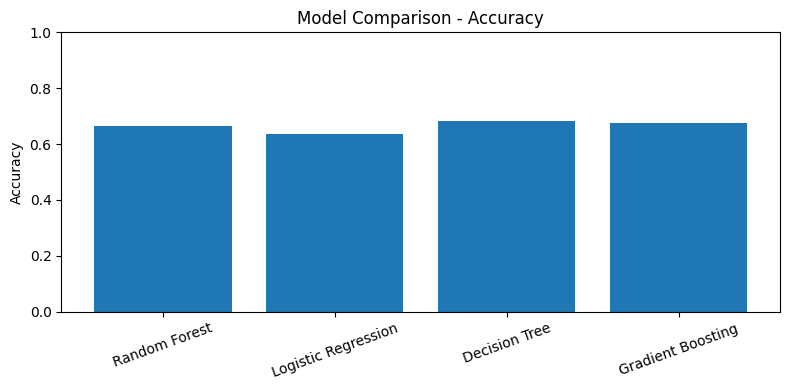

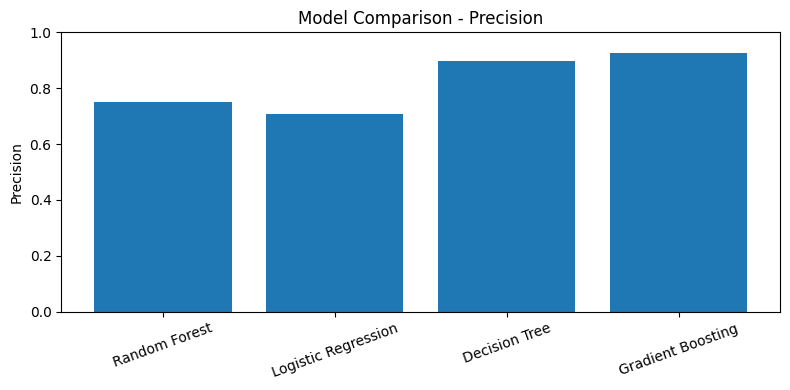

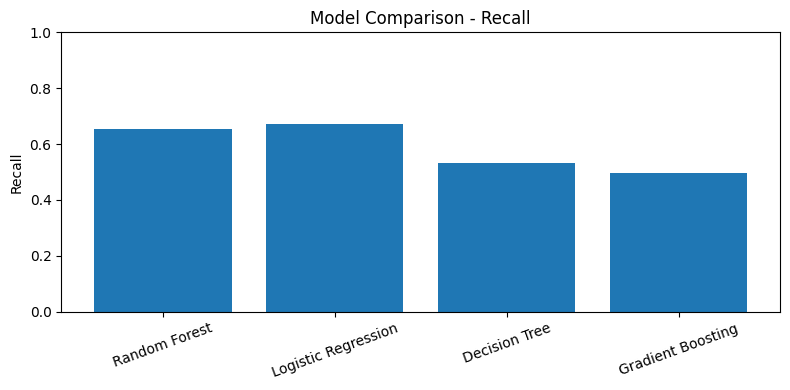

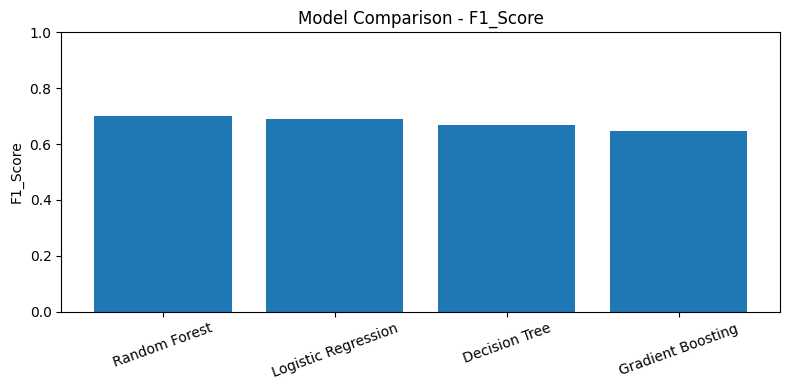

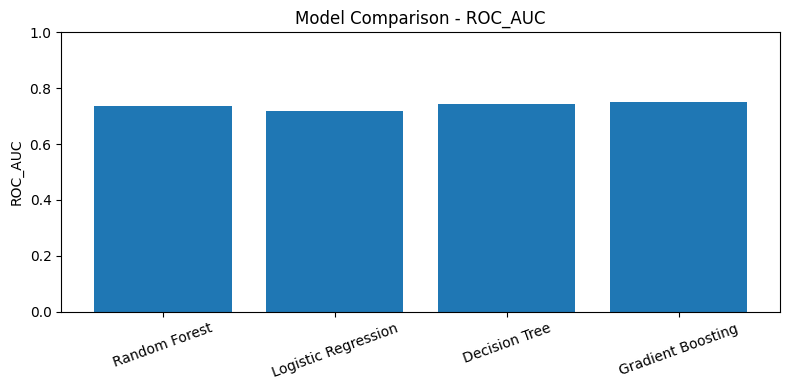

In [21]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1_Score", "ROC_AUC"]

for metric in metrics_to_plot:
    plt.figure(figsize=(8, 4))
    plt.bar(results["Model"], results[metric])
    plt.title(f"Model Comparison - {metric}")
    plt.ylabel(metric)
    plt.ylim(0, 1)
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

## 20. Select the Best Baseline Model

For this project, the primary comparison metric is **F1-score**, because both precision and recall matter when predicting delivery outcomes.

**Why:** Selecting only by accuracy can hide weaknesses in one class. F1-score provides a balance between precision and recall.

The best baseline model is selected automatically from the comparison table.

In [22]:
best_baseline_name = results.loc[0, "Model"]
best_baseline_f1 = results.loc[0, "F1_Score"]

print("Best baseline model:", best_baseline_name)
print("Best baseline F1-score:", round(best_baseline_f1, 4))

Best baseline model: Random Forest
Best baseline F1-score: 0.6993


## Final Model Selection and Tuning
The baseline comparison table above identifies the model with the highest F1-score. The notebook then tunes Logistic Regression as a reference tuned model; compare its held-out F1-score with the baseline results before drawing a final conclusion.

In [23]:
# Tune Logistic Regression because it achieved the highest baseline F1-score.
# F1-score is the primary model-selection metric for this project.

from sklearn.model_selection import RandomizedSearchCV

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lr_for_tuning = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

param_distributions_lr = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__solver": ["liblinear", "lbfgs"],
    "model__class_weight": [None, "balanced"]
}

lr_search = RandomizedSearchCV(
    estimator=lr_for_tuning,
    param_distributions=param_distributions_lr,
    n_iter=10,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

lr_search.fit(X_train, y_train)

best_lr = lr_search.best_estimator_

print("Best Logistic Regression parameters:")
print(lr_search.best_params_)

print("\nBest cross-validation F1-score:",
      round(lr_search.best_score_, 4))


Fitting 5 folds for each of 10 candidates, totalling 50 fits


Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Best Logistic Regression parameters:
{'model__solver': 'lbfgs', 'model__class_weight': None, 'model__C': 0.01}

Best cross-validation F1-score: 0.6975


In [24]:
# Evaluate the tuned Logistic Regression model
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix

y_pred_lr = best_lr.predict(X_test)

# Use probabilities for ROC-AUC when available
if hasattr(best_lr, "predict_proba"):
    y_prob_lr = best_lr.predict_proba(X_test)[:, 1]
else:
    y_prob_lr = None

lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr, zero_division=0)
lr_recall = recall_score(y_test, y_pred_lr, zero_division=0)
lr_f1 = f1_score(y_test, y_pred_lr, zero_division=0)
lr_roc_auc = roc_auc_score(y_test, y_prob_lr) if y_prob_lr is not None else None

print("Tuned Logistic Regression Results")
print("---------------------------------")
print(f"Accuracy : {lr_accuracy:.4f}")
print(f"Precision: {lr_precision:.4f}")
print(f"Recall   : {lr_recall:.4f}")
print(f"F1-score : {lr_f1:.4f}")
if lr_roc_auc is not None:
    print(f"ROC-AUC  : {lr_roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))


Tuned Logistic Regression Results
---------------------------------
Accuracy : 0.6441
Precision: 0.7045
Recall   : 0.6954
F1-score : 0.6999
ROC-AUC  : 0.7232

Classification Report:
              precision    recall  f1-score   support

           0       0.56      0.57      0.56       887
           1       0.70      0.70      0.70      1313

    accuracy                           0.64      2200
   macro avg       0.63      0.63      0.63      2200
weighted avg       0.65      0.64      0.64      2200

Confusion Matrix:
[[504 383]
 [400 913]]


In [25]:
# Compare the tuned Logistic Regression result with the baseline models.
# Use values calculated in this notebook rather than hard-coded scores.

baseline_f1 = dict(zip(results["Model"], results["F1_Score"]))
comparison = baseline_f1.copy()
comparison["Tuned Logistic Regression"] = lr_f1

best_model_name = max(comparison, key=comparison.get)
best_model_f1 = comparison[best_model_name]

print("F1-score comparison:")
for name, score in sorted(comparison.items(), key=lambda x: x[1], reverse=True):
    print(f"{name}: {score:.4f} ({score*100:.2f}%)")

print("\nSelected model based on F1-score:", best_model_name)
print(f"F1-score: {best_model_f1:.4f} ({best_model_f1*100:.2f}%)")

F1-score comparison:
Tuned Logistic Regression: 0.6999 (69.99%)
Random Forest: 0.6993 (69.93%)
Logistic Regression: 0.6883 (68.83%)
Decision Tree: 0.6676 (66.76%)
Gradient Boosting: 0.6478 (64.78%)

Selected model based on F1-score: Tuned Logistic Regression
F1-score: 0.6999 (69.99%)


## Final Conclusion
The model comparison and final selection are based on the F1-scores calculated by running this notebook. The selected model name and score are printed in the previous cell. Results can vary slightly if the dataset or modelling settings are changed.

## Save the Final Model

The selected model is saved so it can be reused later for predictions without retraining.


In [26]:
# Save the best available model

model_candidates = {
    "Logistic Regression": logistic_pipeline,
    "Decision Tree": tree_pipeline,
    "Random Forest": rf_pipeline,
    "Gradient Boosting": gb_pipeline,
    "Tuned Logistic Regression": best_lr
}

final_model = model_candidates[best_model_name]

model_output_path = "/mnt/data/ecommerce_shipment_prediction_model.joblib"
joblib.dump(final_model, model_output_path)

print("Final model saved successfully.")
print("Selected model:", best_model_name)
print("Saved to:", model_output_path)


Final model saved successfully.
Selected model: Tuned Logistic Regression
Saved to: /mnt/data/ecommerce_shipment_prediction_model.joblib
